# Exploratory Data Analysis (EDA)

## Project: Credit Card Default Risk Intelligence & Prediction System

### 1. Introduction

Exploratory Data Analysis (EDA) is performed to
understand the structure, patterns, distributions
and relationships within the credit card dataset.

The objective of this analysis is to identify
customer characteristics and repayment behaviours
associated with credit card default.

### Objectives
- Understand customer demographics.
- Analyse credit limits and bill amounts.
- Examine repayment and payment behaviour.
- Identify patterns associated with default.
- Visualise relationships between variables.
- Generate meaningful insights for future
  machine learning development.

In [4]:
# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# Visualisation settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


### Explanation – Library Imports

The notebook uses the following libraries:

- **Pandas:** loads and manipulates tabular data.
- **NumPy:** supports numerical operations.
- **Matplotlib:** creates plots and charts.
- **Seaborn:** creates statistical visualisations.
- **SciPy:** provides statistical functions for analysis.

The display and plotting settings improve readability. These imports prepare the environment for the EDA tasks.

In [5]:


# Get the uploaded filename
file_name = r"processed datasets\cleaned_UCI_Credit_Card.csv"

# Load dataset
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

Dataset loaded successfully!


### Explanation – Loading the Dataset

The file upload utility allows the cleaned CSV to be selected from the computer. `pd.read_csv()` loads the selected file into a Pandas DataFrame named `df`, which is used throughout this notebook.

Use the cleaned dataset supplied by the project team. The notebook should be run from top to bottom so that `df` is defined before later analysis.

In [6]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nFirst five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

Number of rows: 29995
Number of columns: 25

First five records:


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.00,2,2,1,24,2,2,-1,-1,-2,-2,3913.00,3102.00,689.00,0.00,0.00,0.00,0.00,689.00,0.00,0.00,0.00,0.00,1
1,2,120000.00,2,2,2,26,-1,2,0,0,0,2,2682.00,1725.00,2682.00,3272.00,3455.00,3261.00,0.00,1000.00,1000.00,1000.00,0.00,2000.00,1
2,3,90000.00,2,2,2,34,0,0,0,0,0,0,29239.00,14027.00,13559.00,14331.00,14948.00,15549.00,1518.00,1500.00,1000.00,1000.00,1000.00,5000.00,0
3,4,50000.00,2,2,1,37,0,0,0,0,0,0,46990.00,48233.00,49291.00,28314.00,28959.00,29547.00,2000.00,2019.00,1200.00,1100.00,1069.00,1000.00,0
4,5,50000.00,1,2,1,57,-1,0,-1,0,0,0,8617.00,5670.00,35835.00,20940.00,19146.00,19131.00,2000.00,36681.00,10000.00,9000.00,689.00,679.00,0



Last five records:


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
29990,29996,220000.00,1,3,1,39,0,0,0,0,0,0,188948.00,192815.00,208365.00,88004.00,31237.00,15980.00,8500.00,20000.00,5003.00,3047.00,5000.00,1000.00,0
29991,29997,150000.00,1,3,2,43,-1,-1,-1,-1,0,0,1683.00,1828.00,3502.00,8979.00,5190.00,0.00,1837.00,3526.00,8998.00,129.00,0.00,0.00,0
29992,29998,30000.00,1,2,2,37,4,3,2,-1,0,0,3565.00,3356.00,2758.00,20878.00,20582.00,19357.00,0.00,0.00,22000.00,4200.00,2000.00,3100.00,1
29993,29999,80000.00,1,3,1,41,1,-1,0,0,0,-1,-1645.00,78379.00,76304.00,52774.00,11855.00,48944.00,85900.00,3409.00,1178.00,1926.00,52964.00,1804.00,1
29994,30000,50000.00,1,2,1,46,0,0,0,0,0,0,47929.00,48905.00,49764.00,36535.00,32428.00,15313.00,2078.00,1800.00,1430.00,1000.00,1000.00,1000.00,1


### Explanation – Dataset Dimensions and Preview

The dataset contains **29,995 rows and 25 columns**. Each row represents one customer record. `head()` and `tail()` display the first and last five records to inspect the structure and sample values.

In [7]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 29995 entries, 0 to 29994
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   ID                          29995 non-null  int64  
 1   LIMIT_BAL                   29995 non-null  float64
 2   SEX                         29995 non-null  int64  
 3   EDUCATION                   29995 non-null  int64  
 4   MARRIAGE                    29995 non-null  int64  
 5   AGE                         29995 non-null  int64  
 6   PAY_0                       29995 non-null  int64  
 7   PAY_2                       29995 non-null  int64  
 8   PAY_3                       29995 non-null  int64  
 9   PAY_4                       29995 non-null  int64  
 10  PAY_5                       29995 non-null  int64  
 11  PAY_6                       29995 non-null  int64  
 12  BILL_AMT1                   29995 non-null  float64
 13  BILL_AMT2            

ID                              int64
LIMIT_BAL                     float64
SEX                             int64
EDUCATION                       int64
MARRIAGE                        int64
AGE                             int64
PAY_0                           int64
PAY_2                           int64
PAY_3                           int64
PAY_4                           int64
PAY_5                           int64
PAY_6                           int64
BILL_AMT1                     float64
BILL_AMT2                     float64
BILL_AMT3                     float64
BILL_AMT4                     float64
BILL_AMT5                     float64
BILL_AMT6                     float64
PAY_AMT1                      float64
PAY_AMT2                      float64
PAY_AMT3                      float64
PAY_AMT4                      float64
PAY_AMT5                      float64
PAY_AMT6                      float64
default.payment.next.month      int64
dtype: object

### Explanation – Data Types and Structure

`info()` reports each column's data type and non-null count. The column list confirms the variables available for analysis. This helps distinguish identifiers, demographic variables, repayment-status variables, bill amounts, payment amounts and the target.

In [8]:
print("Descriptive Statistics:")
display(df.describe())

print("\nCategorical Variable Summary:")
display(df[['SEX', 'EDUCATION', 'MARRIAGE']].describe())

Descriptive Statistics:


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
count,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00,29995.00
mean,14999.21,167485.57,1.60,1.84,1.56,35.49,-0.02,-0.13,-0.17,-0.22,-0.27,-0.29,51231.72,49187.12,47020.84,43270.01,40317.97,38878.09,5664.43,5922.05,5226.46,4826.79,4800.09,5216.28,0.22
std,8660.28,129754.92,0.49,0.74,0.52,9.22,1.12,1.20,1.20,1.17,1.13,1.15,73639.13,71176.97,69352.61,64335.89,60800.09,59557.05,16564.53,23042.69,17608.33,15667.37,15279.48,17778.85,0.42
min,1.00,10000.00,1.00,1.00,1.00,21.00,-2.00,-2.00,-2.00,-2.00,-2.00,-2.00,-165580.00,-69777.00,-157264.00,-170000.00,-81334.00,-339603.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,7499.50,50000.00,1.00,1.00,1.00,28.00,-1.00,-1.00,-1.00,-1.00,-1.00,-1.00,3565.00,2986.50,2673.50,2331.00,1768.00,1256.50,1000.00,835.50,390.00,296.00,252.00,117.50,0.00
50%,14999.00,140000.00,2.00,2.00,2.00,34.00,0.00,0.00,0.00,0.00,0.00,0.00,22387.00,21212.00,20090.00,19055.00,18107.00,17080.00,2100.00,2009.00,1800.00,1500.00,1500.00,1500.00,0.00
75%,22499.50,240000.00,2.00,2.00,2.00,41.00,0.00,0.00,0.00,0.00,0.00,0.00,67107.00,64017.00,60172.00,54523.00,50208.00,49205.50,5006.00,5000.00,4506.00,4014.00,4034.50,4000.00,0.00
max,30000.00,1000000.00,2.00,4.00,3.00,79.00,8.00,8.00,8.00,8.00,8.00,8.00,964511.00,983931.00,1664089.00,891586.00,927171.00,961664.00,873552.00,1684259.00,896040.00,621000.00,426529.00,528666.00,1.00



Categorical Variable Summary:


,SEX,EDUCATION,MARRIAGE
count,29995.00,29995.00,29995.00
mean,1.60,1.84,1.56
std,0.49,0.74,0.52
min,1.00,1.00,1.00
25%,1.00,1.00,1.00
50%,2.00,2.00,2.00
75%,2.00,2.00,2.00
max,2.00,4.00,3.00


### Explanation – Descriptive Statistics

`describe()` calculates count, mean, standard deviation, minimum, quartiles and maximum for numerical columns. These statistics summarise the centre and spread of each variable. The separate summary for `SEX`, `EDUCATION` and `MARRIAGE` shows their category-code distributions.

In [9]:
target = 'default.payment.next.month'

print("Target Variable:", target)

print("\nTarget Variable Distribution:")
display(df[target].value_counts())

print("\nTarget Variable Percentage:")
display(df[target].value_counts(normalize=True) * 100)

Target Variable: default.payment.next.month

Target Variable Distribution:


default.payment.next.month
0    23360
1     6635
Name: count, dtype: int64


Target Variable Percentage:


default.payment.next.month
0   77.88
1   22.12
Name: proportion, dtype: float64

### Explanation – Target Variable

The target is `default.payment.next.month`: **0 means no default and 1 means default**. `value_counts()` gives the number of records in each class, while `normalize=True` converts those counts to proportions.

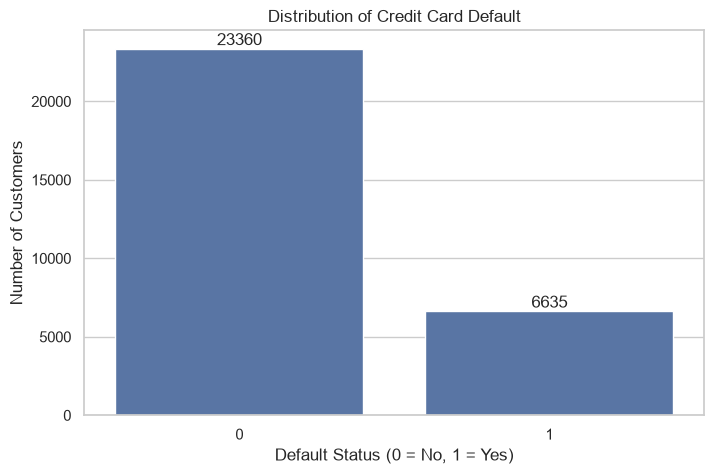

In [10]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x=target
)

plt.title('Distribution of Credit Card Default')
plt.xlabel('Default Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container)

plt.show()

### Inference – Default vs Non-default

Of the **29,995** records, **23,360 (77.88%)** are non-defaults and **6,635 (22.12%)** are defaults. The non-default class is substantially larger, so the target is imbalanced. This matters when evaluating future models: accuracy alone may hide poor detection of the default class.

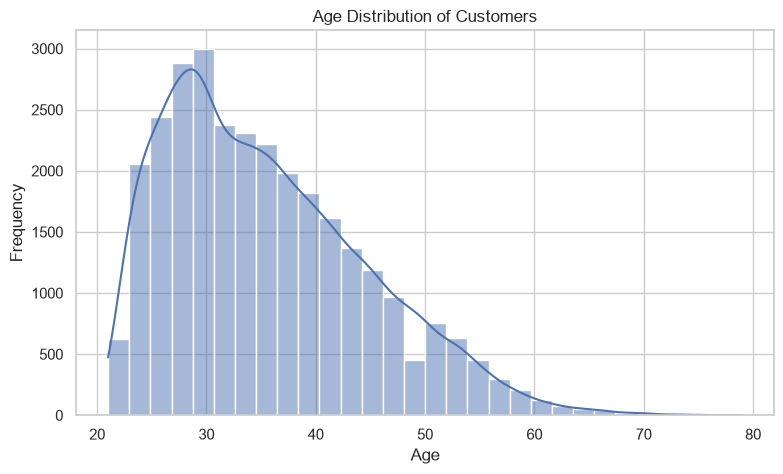

In [11]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='AGE',
    bins=30,
    kde=True
)

plt.title('Age Distribution of Customers')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

### Inference – Age Distribution

The dataset's mean customer age is **35.49 years** and the median is **34 years**. There are **11,010 customers aged 21–30** and **10,711 aged 31–40**. Together, these two groups contain **21,721 customers (72.42%)**, so the dataset is concentrated in the 21–40 age range. Only **272 customers (0.91%)** are older than 60.

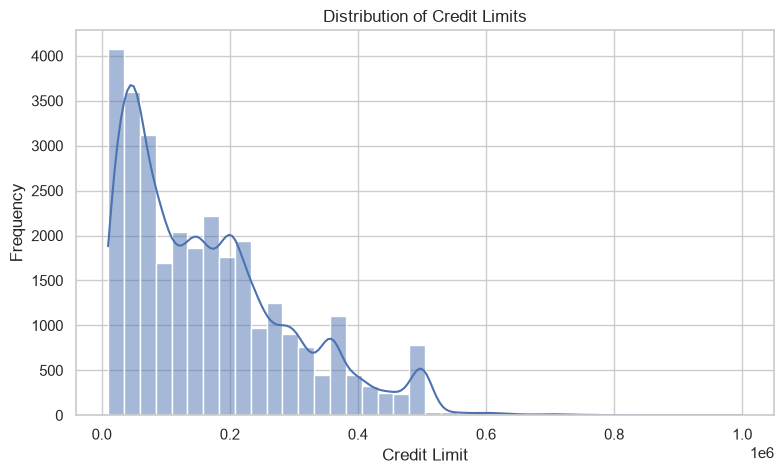

In [12]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='LIMIT_BAL',
    bins=40,
    kde=True
)

plt.title('Distribution of Credit Limits')
plt.xlabel('Credit Limit')
plt.ylabel('Frequency')

plt.show()

### Inference – Credit Limit Distribution

The mean credit limit is approximately **167,486**, while the median is **140,000**; the maximum is **1,000,000**. The mean being above the median, together with the high maximum, suggests a right-skewed distribution: a smaller number of customers have much larger credit limits than the typical customer.

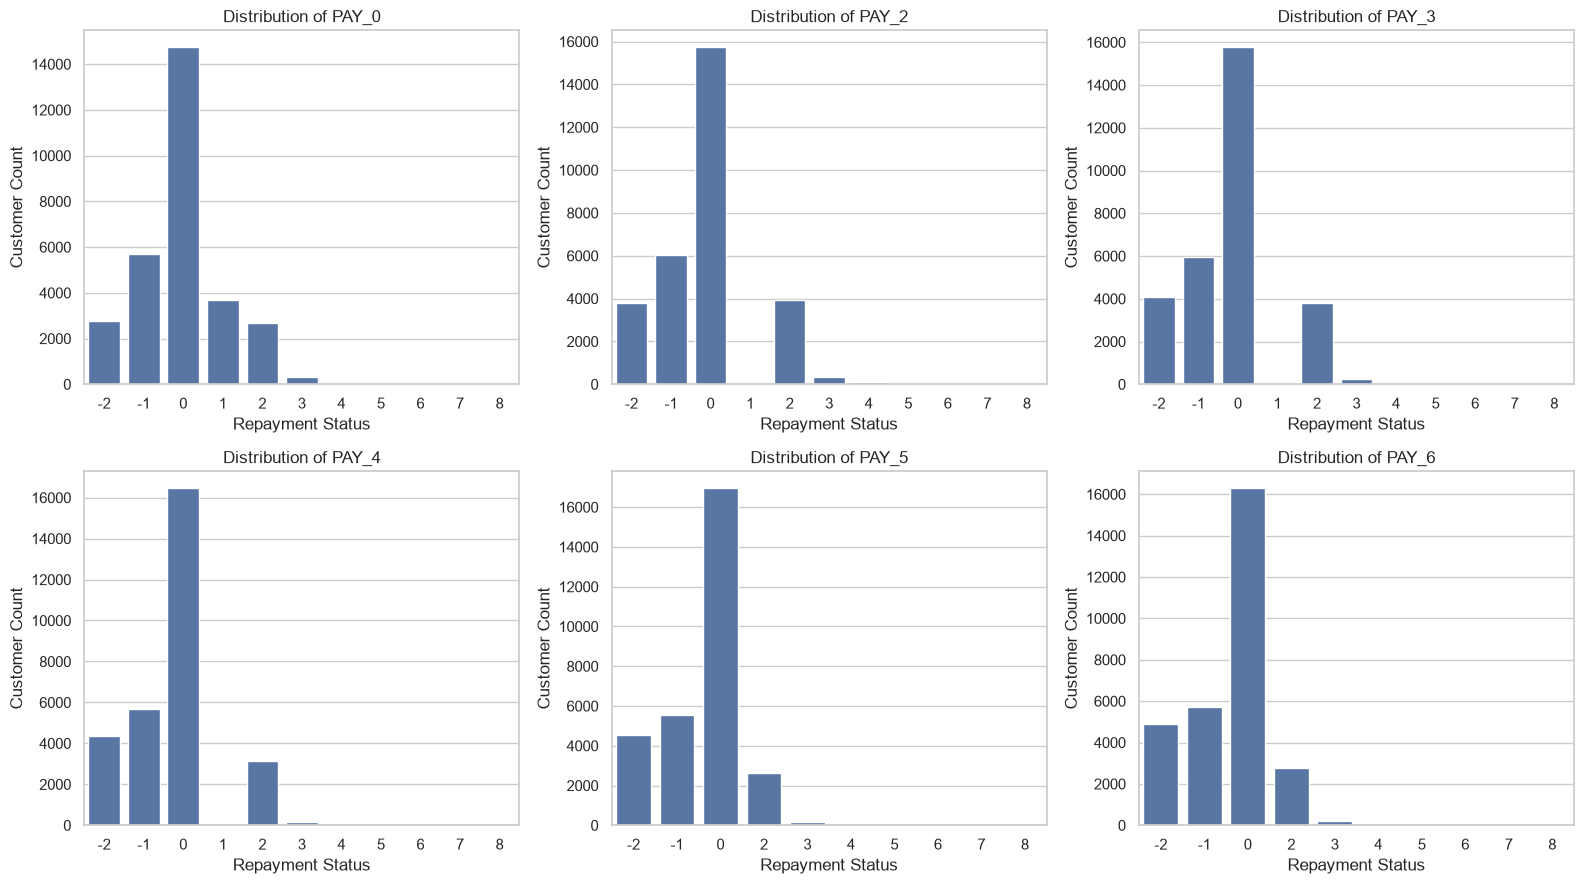

In [13]:
pay_columns = [
    'PAY_0', 'PAY_2', 'PAY_3',
    'PAY_4', 'PAY_5', 'PAY_6'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col, ax in zip(pay_columns, axes.flatten()):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel('Repayment Status')
    ax.set_ylabel('Customer Count')

plt.tight_layout()
plt.show()

### Inference – Repayment Status Distribution

For the most recent repayment-status variable `PAY_0`, the largest category is **0 (14,737 customers)**, followed by **-1 (5,682)** and **-2 (2,759)**. The positive delay categories are less frequent: `PAY_0 = 1` occurs for **3,688 customers**, and `PAY_0 = 2` for **2,666**. The six panels allow the distribution to be compared across the recorded periods.

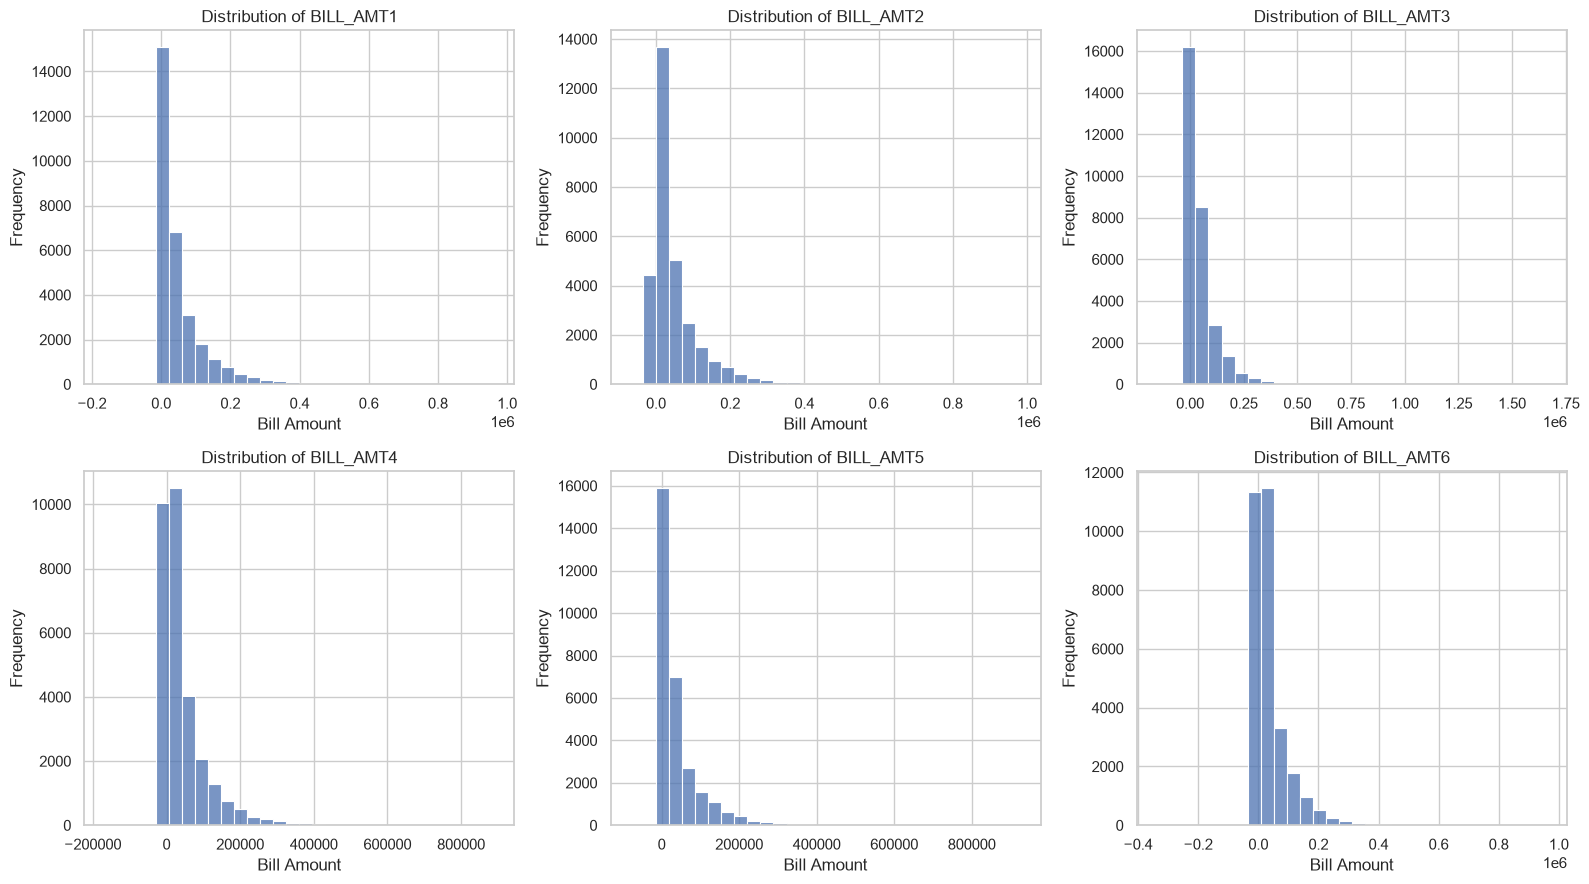

In [14]:
bill_columns = [
    'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
    'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col, ax in zip(bill_columns, axes.flatten()):
    sns.histplot(data=df, x=col, bins=30, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel('Bill Amount')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Inference – Bill Amount Distributions

The six histograms show the distribution of statement bill amounts across the six periods. For `BILL_AMT1`, the mean is approximately **51,232**, while the median is **22,387** and the maximum is **964,511**. The large gap between mean and median indicates a strongly right-skewed distribution, with some very large bill amounts.

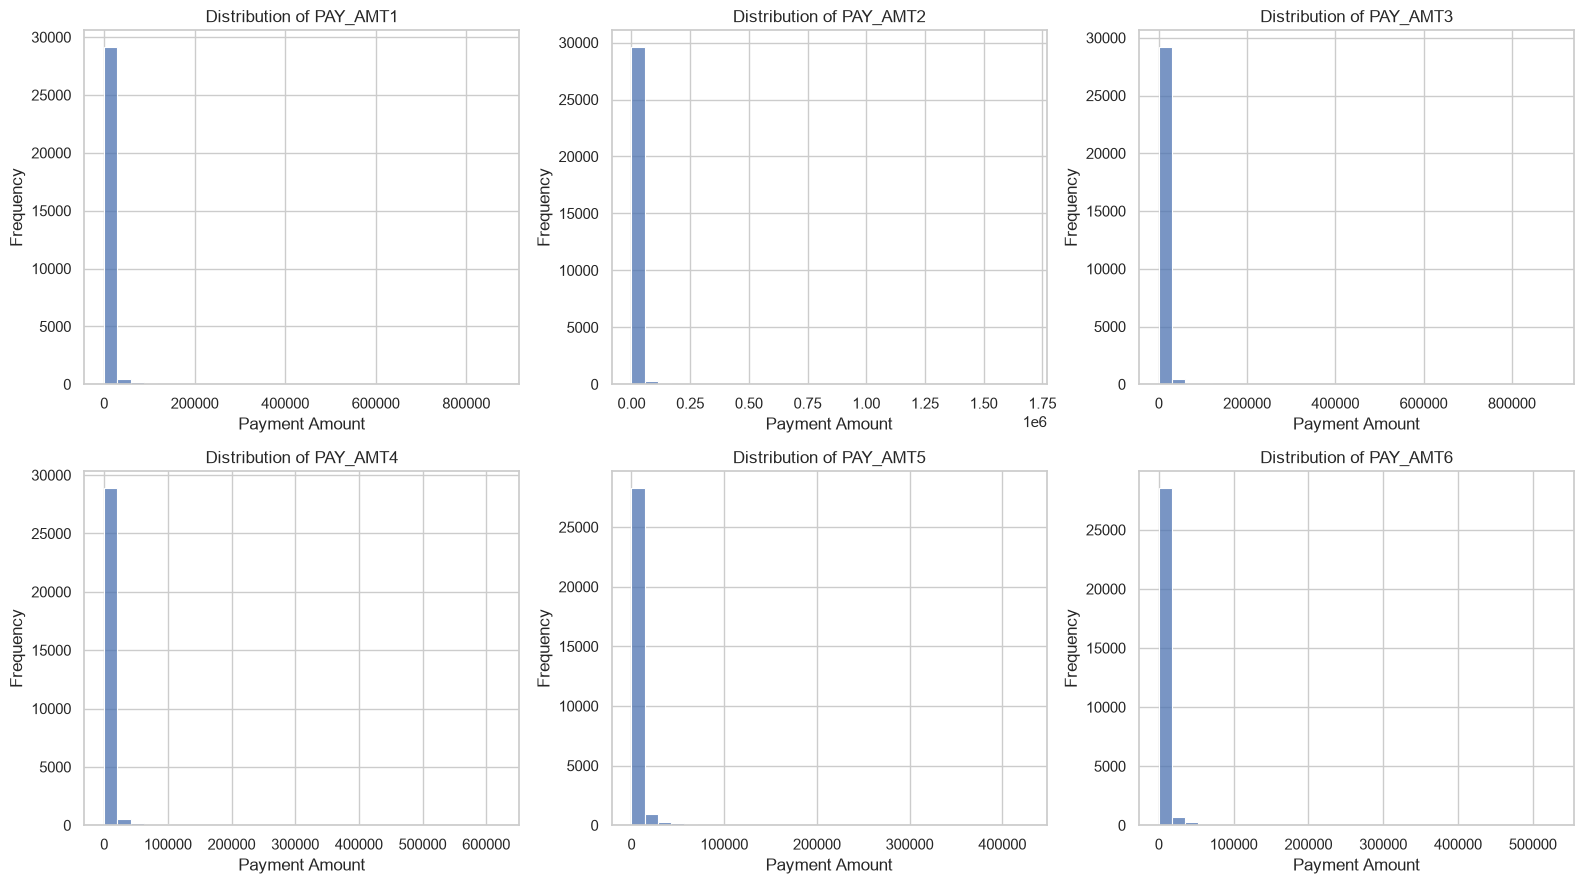

In [15]:
payment_columns = [
    'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
    'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col, ax in zip(payment_columns, axes.flatten()):
    sns.histplot(data=df, x=col, bins=30, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel('Payment Amount')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Inference – Payment Amount Distributions

The six histograms show previous payment amounts across the six periods. They allow us to compare the frequency of small and large payments and observe whether payment distributions are skewed. The distributions should be interpreted alongside bill amounts and repayment-status history; a payment amount alone does not establish whether a customer paid the full amount due.

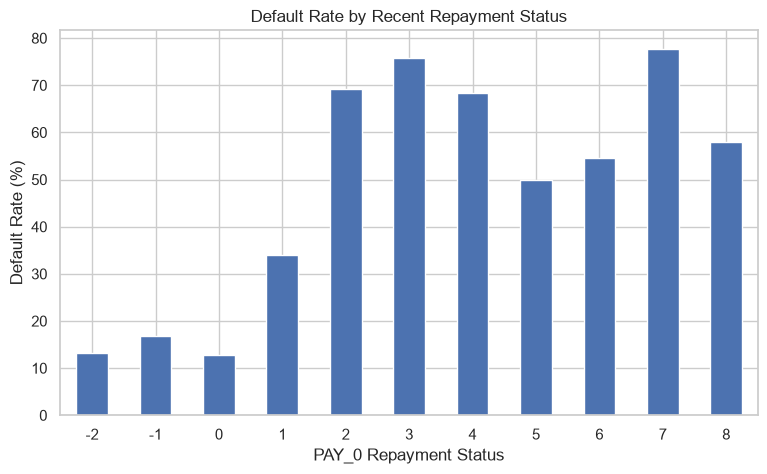

PAY_0
-2   13.23
-1   16.79
 0   12.81
 1   33.95
 2   69.13
 3   75.78
 4   68.42
 5   50.00
 6   54.55
 7   77.78
 8   57.89
Name: default.payment.next.month, dtype: float64

In [16]:
repayment_default = (
    df.groupby('PAY_0')[target].mean() * 100
)

plt.figure(figsize=(9, 5))

repayment_default.plot(kind='bar')

plt.title('Default Rate by Recent Repayment Status')
plt.xlabel('PAY_0 Repayment Status')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)

plt.show()

display(repayment_default)

### Inference – Recent Repayment Status vs Default

The observed default rate is **12.81%** for `PAY_0 = 0`, **33.95%** for `PAY_0 = 1`, and **69.13%** for `PAY_0 = 2`. It reaches **75.78%** for `PAY_0 = 3` (although this category has only 322 records). This pattern shows a strong association between more severe recent repayment delay and next-month default. It is an association, not proof of causation.

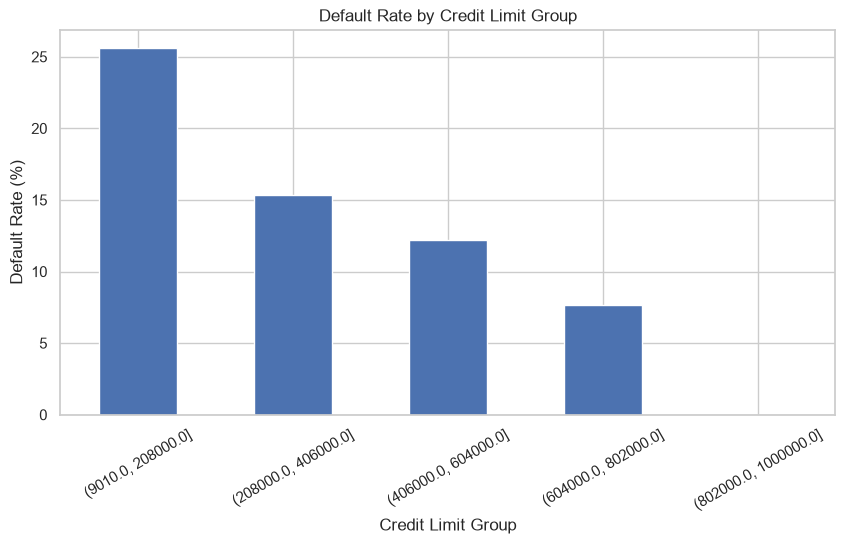

credit_limit_group
(9010.0, 208000.0]      25.61
(208000.0, 406000.0]    15.35
(406000.0, 604000.0]    12.23
(604000.0, 802000.0]     7.69
(802000.0, 1000000.0]    0.00
Name: default.payment.next.month, dtype: float64

In [17]:
df['credit_limit_group'] = pd.cut(
    df['LIMIT_BAL'],
    bins=5
)

credit_default = (
    df.groupby('credit_limit_group', observed=False)[target]
    .mean() * 100
)

plt.figure(figsize=(10, 5))

credit_default.plot(kind='bar')

plt.title('Default Rate by Credit Limit Group')
plt.xlabel('Credit Limit Group')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=30)

plt.show()

display(credit_default)

### Inference – Credit Limit Group vs Default

With the five equal-width `LIMIT_BAL` bins used in this plot, the first group (9,010–208,000) contains **20,375 customers** and has a default rate of **25.61%**. The next groups have rates of **15.35%** (7,816 customers), **12.23%** (1,725 customers), and **7.69%** (78 customers). The final group contains only **one customer**, so its rate is not meaningful for comparison. Overall, the larger groups show lower observed default rates at higher credit limits; this does not establish causation.

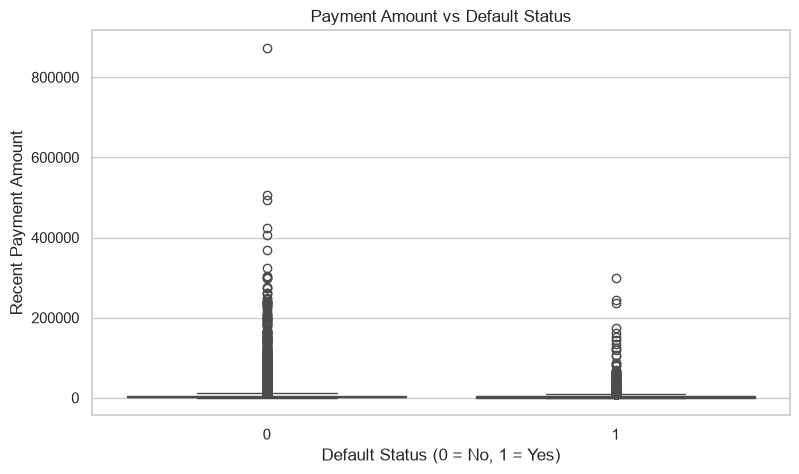

In [18]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x=target,
    y='PAY_AMT1'
)

plt.title('Payment Amount vs Default Status')
plt.xlabel('Default Status (0 = No, 1 = Yes)')
plt.ylabel('Recent Payment Amount')

plt.show()

### Inference – Payment Amount vs Default

The mean `PAY_AMT1` is approximately **6,308.29** for non-defaulting customers and **3,397.56** for defaulting customers. The medians are **2,460** and **1,639**, respectively. Thus, the defaulting group has lower recent payment amounts in this dataset. The box plot also shows the spread and extreme values; payment amount alone does not explain the reason for default.

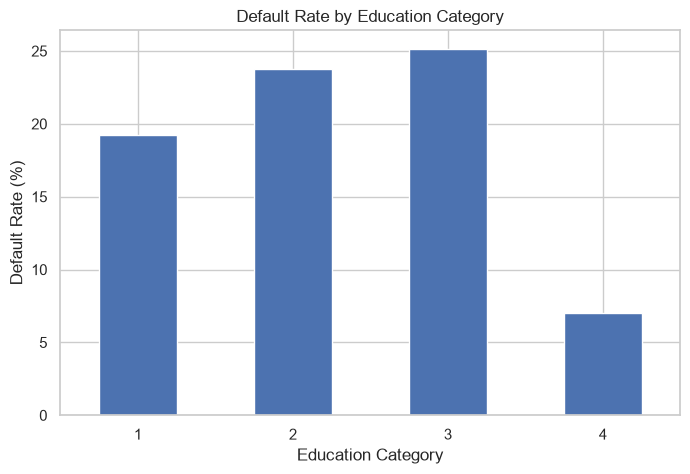

EDUCATION
1   19.24
2   23.73
3   25.16
4    7.05
Name: default.payment.next.month, dtype: float64

In [19]:
education_default = (
    df.groupby('EDUCATION')[target].mean() * 100
)

plt.figure(figsize=(8, 5))

education_default.plot(kind='bar')

plt.title('Default Rate by Education Category')
plt.xlabel('Education Category')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=0)

plt.show()

display(education_default)

### Inference – Education Category vs Default

The observed default rates are **19.24%** for education code 1 (10,584 customers), **23.73%** for code 2 (14,027 customers), **25.16%** for code 3 (4,916 customers), and **7.05%** for code 4 (468 customers). The category codes should be interpreted using the dataset documentation. The smaller size of category 4 should be kept in mind, and these descriptive differences do not imply that education causes default.

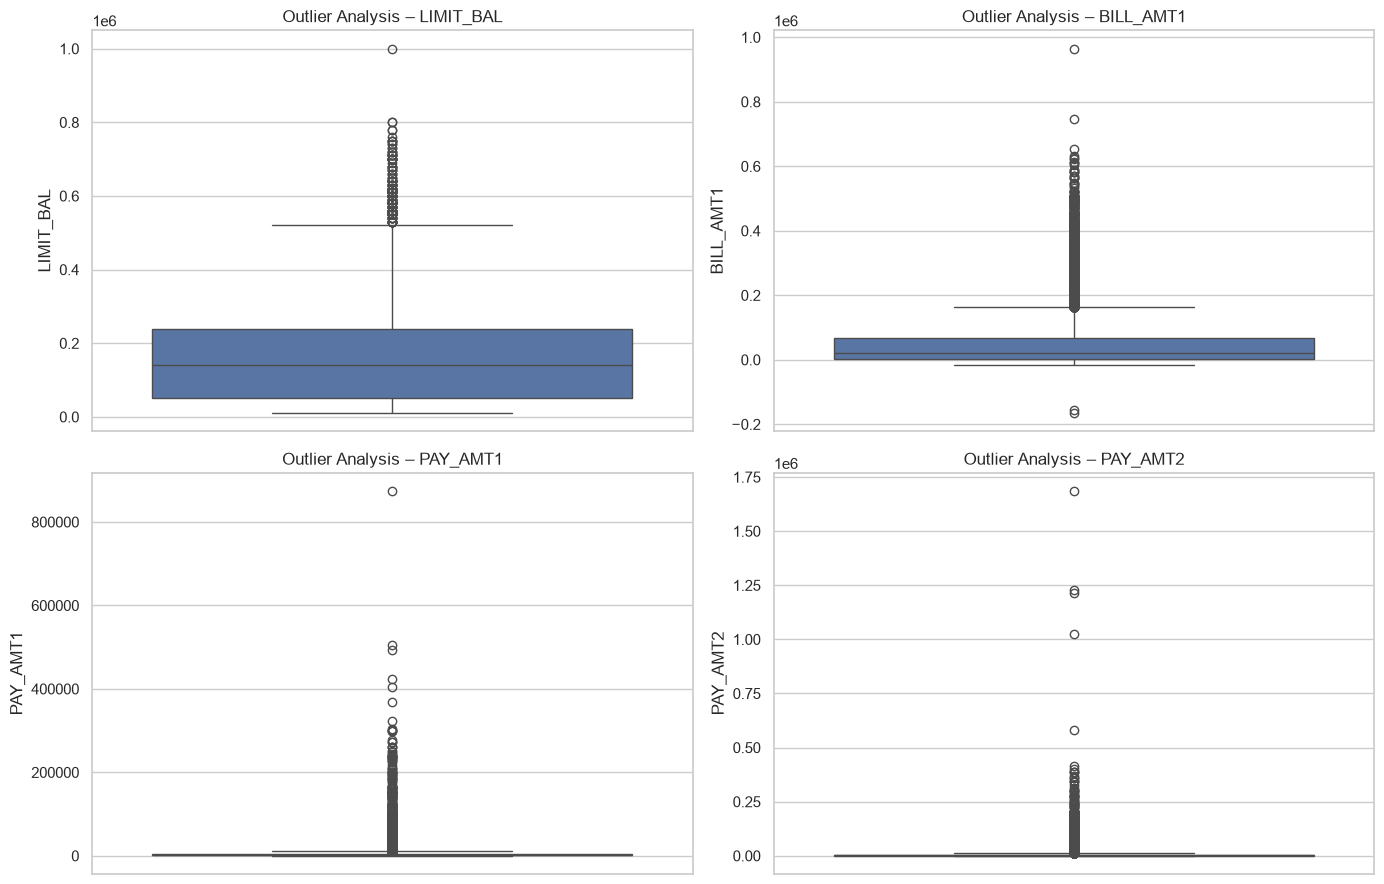

In [20]:
outlier_columns = [
    'LIMIT_BAL',
    'BILL_AMT1',
    'PAY_AMT1',
    'PAY_AMT2'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for col, ax in zip(outlier_columns, axes.flatten()):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(f'Outlier Analysis – {col}')

plt.tight_layout()
plt.show()

### Inference – Outlier Analysis

The box plots flag potential extreme values in `LIMIT_BAL`, `BILL_AMT1`, `PAY_AMT1` and `PAY_AMT2`. For example, `BILL_AMT1` has a median of **22,387** and a maximum of **964,511**. Such points may be genuine high-value customer records rather than data errors. They should be investigated before any removal or transformation.

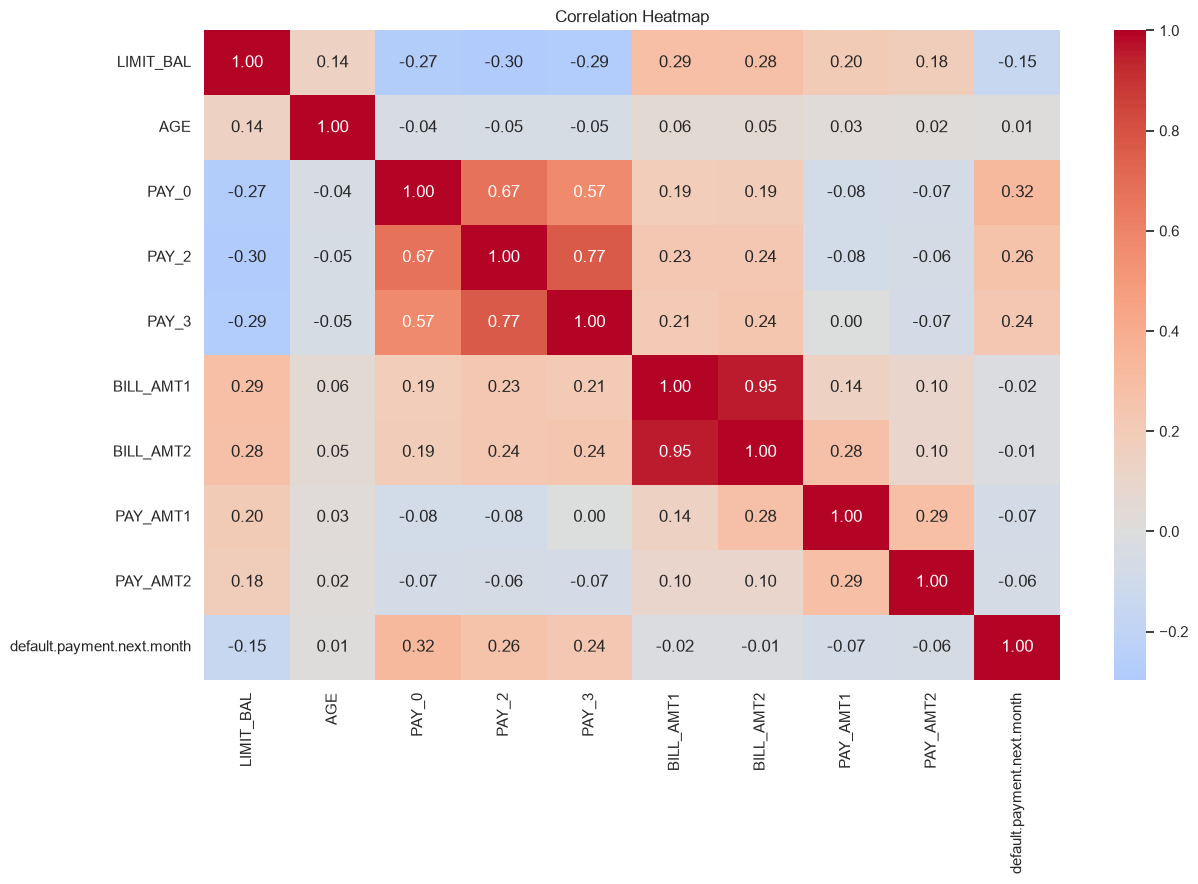

In [21]:
correlation_columns = [
    'LIMIT_BAL',
    'AGE',
    'PAY_0',
    'PAY_2',
    'PAY_3',
    'BILL_AMT1',
    'BILL_AMT2',
    'PAY_AMT1',
    'PAY_AMT2',
    target
]

correlation_matrix = df[
    correlation_columns
].corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### Inference – Correlation Analysis

The Pearson correlation with the default target is approximately **0.325 for `PAY_0`**, **0.263 for `PAY_2`**, **0.235 for `PAY_3`**, and **-0.153 for `LIMIT_BAL`**. Among the selected variables, the repayment-status variables have the strongest positive linear associations with the target. These are correlations, not causal effects; the repayment-status codes are ordinal categories, so their numeric correlations should also be interpreted cautiously.

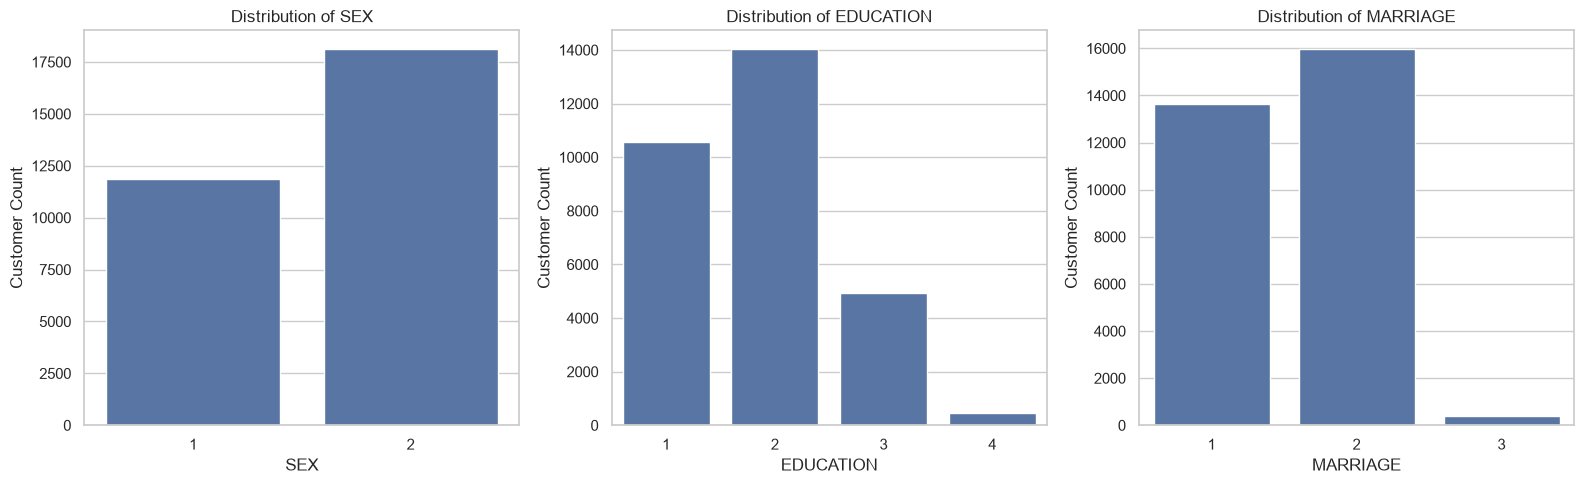

In [22]:
categorical_columns = [
    'SEX',
    'EDUCATION',
    'MARRIAGE'
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for col, ax in zip(categorical_columns, axes):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Customer Count')

plt.tight_layout()
plt.show()

### Inference – Demographic Distributions

The three count plots compare the number of records in each coded category of `SEX`, `EDUCATION` and `MARRIAGE`. Use the bar heights and category counts to describe which categories are most common. The codes should be interpreted with the dataset's data dictionary rather than treated as meaningful numeric magnitudes.

In [23]:
print("KEY DATASET FINDINGS")
print("-" * 40)

print("Total customers:", len(df))

print(
    "Non-default customers:",
    (df[target] == 0).sum()
)

print(
    "Default customers:",
    (df[target] == 1).sum()
)

print(
    "Default percentage:",
    round((df[target] == 1).mean() * 100, 2),
    "%"
)

print(
    "Average customer age:",
    round(df['AGE'].mean(), 2)
)

print(
    "Average credit limit:",
    round(df['LIMIT_BAL'].mean(), 2)
)

print(
    "Missing values:",
    df.isnull().sum().sum()
)

KEY DATASET FINDINGS
----------------------------------------
Total customers: 29995
Non-default customers: 23360
Default customers: 6635
Default percentage: 22.12 %
Average customer age: 35.49
Average credit limit: 167485.57
Missing values: 0


### Explanation – Summary Statistics

This cell calculates the total number of records, counts of default and non-default customers, default percentage, mean age, mean credit limit and total missing-value count. These summary values provide a compact numerical recap of the dataset used in the EDA.

# Conclusion

Exploratory Data Analysis was performed on **29,995 customer records and 25 columns** in the cleaned credit-card dataset.

Key findings from the analysis:

- **22.12%** of records belong to the default class, compared with **77.88%** in the non-default class.
- The dataset is concentrated in the **21–40 age range**, which contains **72.42%** of customers.
- Recent repayment status is associated with default: the observed default rate is **12.81%** at `PAY_0 = 0`, **33.95%** at `PAY_0 = 1`, and **69.13%** at `PAY_0 = 2`.
- The mean recent payment amount is lower for defaulting customers (**3,397.56**) than for non-defaulting customers (**6,308.29**).
- Several financial variables have highly skewed distributions and potential outliers that should be investigated rather than automatically removed.
- Correlation results indicate associations, not causation.

These descriptive findings can inform subsequent feature analysis and preprocessing. **No machine-learning model is trained in this Level 1 EDA notebook.**